In [1]:
# This dataset is from Kaggle
# It contains information about a non-store company's retail operations registered on UK.
# It has data on 2009 - 2011

## Variable Description

| Variable | Type | Description |
|---|---|---|
| `InvoiceNo` | Nominal / String | A 6-digit integral number uniquely assigned to each transaction. If this code starts with the letter `C`, it indicates a cancellation. |
| `StockCode` | Nominal / String | A 5-digit product code uniquely assigned to each distinct product. |
| `Description` | Nominal / String | Product (item) name. |
| `Quantity` | Numeric / Integer | The quantity of each product (item) per transaction. |
| `InvoiceDate` | DateTime | The date and time when a transaction was generated. |
| `UnitPrice` | Numeric / Float | Product price per unit in GBP. |
| `CustomerID` | Nominal / String | A 5-digit customer number. It may contain missing values. |
| `Country` | Nominal / String | The country where the customer resides. |

In [2]:
import pandas as pd

In [3]:
path = "online_retail_II.csv"
# If this was a excel file then the code would be changed to: 
# df = pd.read_excel(path, parse_dates=["InvoiceDate"])
df = pd.read_csv("online_retail_II.csv", parse_dates=["InvoiceDate"])

In [4]:
print(df.shape)

(1067371, 8)


In [5]:
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [7]:
# Now move in to data cleaning and preprocessing. 


## Data Cleaning

In [8]:
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [9]:
# According to the data dictionary, the columns "Description" and "Customer ID" have missing values.

In [ ]:
pd.set_option("display.float_format", "{:,.2f}".format) # Tells pandas show floating point values with commas and 2 decimal places. 123456.67 = 123,456.67
df[["Quantity", "Price"]].describe()

,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


I this table there is hugh differnce between mean and std. Which means the speard of the data is too big. But this has happens because of some outlier values like 80, 995. The Quatile range are between 1 -10 and 1.25 - 4.15 which mean most of the data stays between those values. In this data set currently std cannot be trusted. 
Also there are minus values in quanity and price, most likely they are debt to pay or the cancelations of oders.

In [11]:
print(df["InvoiceDate"].min(), df["InvoiceDate"].max())

2009-12-01 07:45:00 2011-12-09 12:50:00


In [12]:
# Known problem areas. This is important. 
print("Cancellations:", df["Invoice"].str.startswith("C").sum())


Cancellations: 19494


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34335


In [14]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())

Quantity <= 0: 22950
Price <= 0: 6207


In [15]:
# loc gives the rows and columns that satisfy the condition.
non_positive_quantity = df.loc[df["Quantity"] <= 0, ["Invoice", "Quantity"]]
non_positive_quantity

,Invoice,Quantity
178,C489449,-12
179,C489449,-6
180,C489449,-4
181,C489449,-6
182,C489449,-12
...,...,...
1065910,C581490,-11
1067002,C581499,-1
1067176,C581568,-5
1067177,C581569,-1


In [16]:
# Create a log array for each and every change
log = [("raw", len(df))]

In [17]:
print(log)

[('raw', 1067371)]


In [18]:
# Start the cleaning process by removing the missing values on "Customer ID"
# Because for clustering, we need to have a customer ID for each transaction.

df["missing_id"] = df["Customer ID"].isna()
print(df.groupby("Country")["missing_id"].mean().sort_values(ascending=False).head())

Country
Hong Kong     1.00
Bermuda       1.00
Bahrain       0.53
Unspecified   0.31
RSA           0.27
Name: missing_id, dtype: float64


Every missing value customer is not from UK. So we can safely remove them.


In [19]:
df = df.dropna(subset=["Customer ID"])
log.append(("drop missing Customer ID", len(df)))

In [20]:
df.isna().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
missing_id     0
dtype: int64

In [21]:
is_cancel = df["Invoice"].str.startswith("C")
returns = df[is_cancel].copy()
df = df[~is_cancel]
log.append(("remove cancellations", len(df)))

In [22]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,missing_id
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False


In [23]:
# This is suppose to check. Every variable should be checked whether it is matched the description.

# This checks for the unusual stock codes. The stock codes should be 5 digit numbers.
codes = df["StockCode"].astype(str)
print(df[~codes.str.match(r"^\d{5}")]["StockCode"].value_counts())

# This remove the codes that are not 5 digit numbers.
df = df[codes.str.match(r"^\d{5}")]
log.append(("non-product codes", len(df)))

StockCode
POST            1838
M                716
C2               253
BANK CHARGES      32
ADJUST            32
PADS              18
DOT               16
TEST001           11
D                  5
ADJUST2            3
SP1002             2
TEST002            1
Name: count, dtype: int64


In [24]:
# Invalid quantity / price
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
log.append(("qty/price <= 0", len(df)))

In [25]:
print("Duplicates:", df.duplicated().sum())
print(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

Duplicates: 26055
    Invoice StockCode                       Description  Quantity  \
379  489517     21491   SET OF THREE VINTAGE GIFT WRAPS         1   
391  489517     21491   SET OF THREE VINTAGE GIFT WRAPS         1   
365  489517     21821  GLITTER STAR GARLAND WITH BELLS          1   
386  489517     21821  GLITTER STAR GARLAND WITH BELLS          1   
363  489517     21912          VINTAGE SNAKES & LADDERS         1   
371  489517     21912          VINTAGE SNAKES & LADDERS         1   
394  489517     21912          VINTAGE SNAKES & LADDERS         1   
362  489517     21913    VINTAGE SEASIDE JIGSAW PUZZLES         1   
385  489517     21913    VINTAGE SEASIDE JIGSAW PUZZLES         1   
368  489517     22130  PARTY CONE CHRISTMAS DECORATION          6   

            InvoiceDate  Price  Customer ID         Country  missing_id  
379 2009-12-01 11:34:00   1.95    16,329.00  United Kingdom       False  
391 2009-12-01 11:34:00   1.95    16,329.00  United Kingdom       False  


In [26]:
df = df.drop_duplicates()
log.append(("duplicates", len(df)))

In [27]:
# Create new column for total price
df["Revenue"] = df["Quantity"] * df["Price"]

In [28]:
print(pd.DataFrame(log, columns=["step", "rows_left"]))

                       step  rows_left
0                       raw    1067371
1  drop missing Customer ID     824364
2      remove cancellations     805620
3         non-product codes     802693
4            qty/price <= 0     802632
5                duplicates     776577


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 776577 entries, 0 to 1067369
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      776577 non-null  object        
 1   StockCode    776577 non-null  object        
 2   Description  776577 non-null  object        
 3   Quantity     776577 non-null  int64         
 4   InvoiceDate  776577 non-null  datetime64[ns]
 5   Price        776577 non-null  float64       
 6   Customer ID  776577 non-null  float64       
 7   Country      776577 non-null  object        
 8   missing_id   776577 non-null  bool          
 9   Revenue      776577 non-null  float64       
dtypes: bool(1), datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 60.0+ MB


In [30]:
df = df.drop(columns="missing_id")

In [31]:
df["Customer ID"] = df["Customer ID"].astype(int)

In [41]:
# This dataset one raw represent an item of a transaction. 
# So, if a customer bought 3 items, then there will be 3 raws for that transaction.

# We need to group the data by customers to train a proper model

snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Basket (invoice) level first, so averages are per order, not per line
baskets = df.groupby(["Customer ID", "Invoice"]).agg(
    basket_value=("Revenue", "sum"),
    date=("InvoiceDate", "max"),
).reset_index()

baskets.head()


,Customer ID,Invoice,basket_value,date
0,12346,499763,27.05,2010-03-02 13:08:00
1,12346,513774,142.31,2010-06-28 13:53:00
2,12346,541431,"77,183.60",2011-01-18 10:01:00
3,12347,529924,611.53,2010-10-31 14:20:00
4,12347,537626,711.79,2010-12-07 14:57:00


In [33]:
cust = baskets.groupby("Customer ID").agg(
    Recency=("date", lambda s: (snapshot - s.max()).days), #LAMBDA FUNCTION: This is one line function delaration.
    Frequency=("Invoice", "nunique"),
    Monetary=("basket_value", "sum"),
    AvgBasket=("basket_value", "mean"),
    Tenure=("date", lambda s: (s.max() - s.min()).days),
)

cust["UniqueProducts"] = df.groupby("Customer ID")["StockCode"].nunique()

In [34]:
print(cust.head())

             Recency  Frequency  Monetary  AvgBasket  Tenure  UniqueProducts
Customer ID                                                                 
12346            326          3 77,352.96  25,784.32     321              25
12347              2          8  4,921.53     615.19     402             126
12348             75          5  1,658.40     331.68     362              24
12349             19          3  3,678.69   1,226.23     570             137
12350            310          1    294.40     294.40       0              16


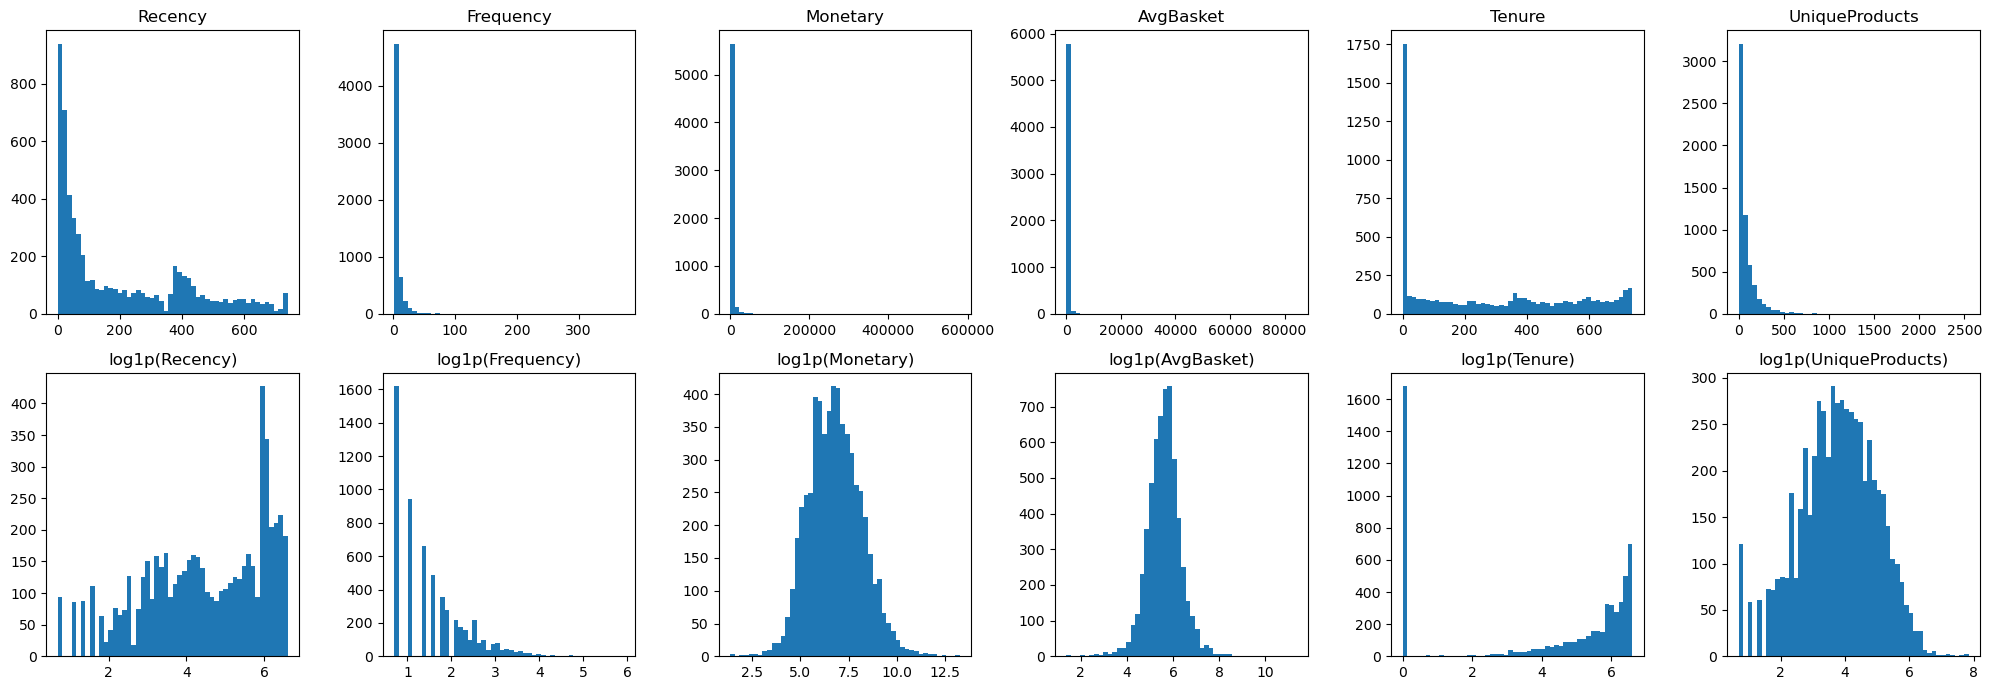

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

cols = ["Recency", "Frequency", "Monetary", "AvgBasket", "Tenure", "UniqueProducts"]

fig, ax = plt.subplots(2, len(cols), figsize=(20, 7))
for i, c in enumerate(cols):
    ax[0, i].hist(cust[c], bins=50)
    ax[0, i].set_title(c)
    ax[1, i].hist(np.log1p(cust[c].clip(lower=0)), bins=50) # log values compress the larger value to smaller values. 
    ax[1, i].set_title(f"log1p({c})")

plt.tight_layout()
plt.show()

Recency              Axes(0.125,0.53;0.227941x0.35)
Frequency         Axes(0.398529,0.53;0.227941x0.35)
Monetary          Axes(0.672059,0.53;0.227941x0.35)
AvgBasket            Axes(0.125,0.11;0.227941x0.35)
Tenure            Axes(0.398529,0.11;0.227941x0.35)
UniqueProducts    Axes(0.672059,0.11;0.227941x0.35)
dtype: object

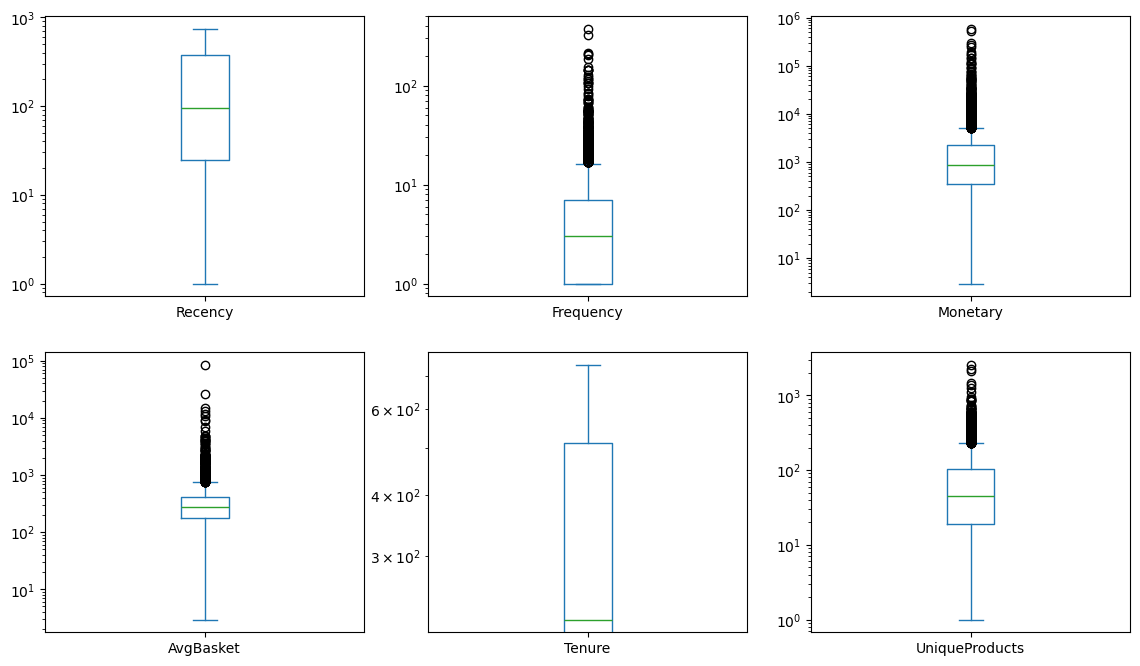

In [36]:
cust[cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(14, 8), logy=True)

In [37]:
# These results shows highly left skewed distributions. 
# Also there are few comsiderable outliers, speacially the values around 80000. 



In [38]:
raw = pd.read_csv("online_retail_II.csv", parse_dates=["InvoiceDate"])
raw["Invoice"] = raw["Invoice"].astype(str)

returns = raw[raw["Invoice"].str.startswith("C") & raw["Customer ID"].notna()].copy()
returns["Customer ID"] = returns["Customer ID"].astype(int)
returns["Revenue"] = (returns["Quantity"] * returns["Price"]).abs()

# Same non-product filter as before, so fees and postage refunds don't count as returns
returns = returns[returns["StockCode"].astype(str).str.match(r"^\d{5}")]

In [39]:
print(returns.shape)

(17933, 9)


In [40]:
returns[returns["Customer ID"] == 12346]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,"77,183.60"


In [42]:
cust

,Recency,Frequency,Monetary,AvgBasket,Tenure,UniqueProducts
Customer ID,,,,,,
12346,326,3,"77,352.96","25,784.32",321,25
12347,2,8,"4,921.53",615.19,402,126
12348,75,5,"1,658.40",331.68,362,24
12349,19,3,"3,678.69","1,226.23",570,137
12350,310,1,294.40,294.40,0,16
...,...,...,...,...,...,...
18283,4,22,"2,658.95",120.86,654,351
18284,432,1,411.68,411.68,0,27
18285,661,1,377.00,377.00,0,11


In [45]:
returned = returns.groupby("Customer ID")["Revenue"].sum()

In [48]:
cust["Returns"] = returned.reindex(cust.index).fillna(0)
cust["NetMonetary"] = cust["Monetary"] - cust["Returns"]
cust["ReturnRate"] = (cust["Returns"] / cust["Monetary"]).clip(upper=1)

In [49]:
cust.loc[[12346, 12347]]

,Recency,Frequency,Monetary,AvgBasket,Tenure,UniqueProducts,Returns,NetMonetary,ReturnRate
Customer ID,,,,,,,,,
12346,326,3,"77,352.96","25,784.32",321,25,"77,183.60",169.36,1.00
12347,2,8,"4,921.53",615.19,402,126,0.00,"4,921.53",0.00


In [50]:
print((cust["NetMonetary"] <= 0).sum())

20


In [51]:
cust = cust[cust["NetMonetary"] > 0]
print(len(cust))

5832


In [54]:
print((cust["ReturnRate"] == 1).sum())

0


In [55]:
print(cust["ReturnRate"].describe())
print("Never returned:", (cust["ReturnRate"] == 0).mean().round(2))
print("Rate > 0.5:", (cust["ReturnRate"] > 0.5).sum())

count   5,832.00
mean        0.02
std         0.06
min         0.00
25%         0.00
50%         0.00
75%         0.01
max         1.00
Name: ReturnRate, dtype: float64
Never returned: 0.59
Rate > 0.5: 20
